![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.6 The Boosted Model of Causal Inference (causalXGBoost)



## Overview

**C-XGBoost** is a tree-boosting method for estimating individual and average treatment effects from observational data. It belongs to the *outcome regression* family of causal inference methods — the same conceptual family as TARNet and DragonNet — but replaces neural networks with XGBoost. The result is a model that brings DragonNet-style causal masking to boosted trees, combining the counterfactual reasoning of neural causal models with XGBoost's well-known strengths on tabular data: robustness to irregular boundaries, excellent calibration on medium-sized datasets, and minimal tuning overhead.

The core idea is simple: train **one** XGBoost model with **two output heads** that simultaneously predict potential outcomes under control ($\hat{Q}_0(x)$) and treatment ($\hat{Q}_1(x)$). The individual treatment effect falls out as their difference.

### Causal Setup

C-XGBoost operates within the **potential outcomes framework**. For each unit $i$, two potential outcomes exist — $Y_i(0)$ under control and $Y_i(1)$ under treatment — but only one is observed:

$$Y_i = T_i\, Y_i(1) + (1 - T_i)\, Y_i(0)$$

The quantities of interest are:

$$
\tau_i = Y_i(1) - Y_i(0) \quad \text{(ITE — individual treatment effect)}
$$
$$
\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x] \quad \text{(CATE — conditional average treatment effect)}
$$
$$
\text{ATE} = \mathbb{E}[Y(1) - Y(0)] \quad \text{(population average treatment effect)}
$$

These are identifiable from observational data $(X, T, Y)$ under three standard assumptions: **consistency** (SUTVA — no interference between units), **ignorability** (no unmeasured confounders: $(Y(0), Y(1)) \perp T \mid X$), and **overlap** ($0 < e(x) < 1$, where $e(x) = P(T=1 \mid X=x)$). If any of these fail — especially ignorability — the estimates break down.

### The Two-Head Architecture

C-XGBoost learns two conditional expectation functions inside a single model:

$$\hat{Q}_0(x) \approx E[Y(0) \mid X = x], \qquad \hat{Q}_1(x) \approx E[Y(1) \mid X = x]$$

The ITE estimate is then:

$$\hat{\tau}(x) = \hat{Q}_1(x) - \hat{Q}_0(x)$$

The heads **share tree structure** but have **separate leaf values**. This is the key design choice: shared splits mean the model learns a common feature-space partitioning that generalizes across both heads, so counterfactuals are borrowed from structurally similar units rather than extrapolated blindly.

### The Masked Loss

Each training unit contributes gradient signal to *only* the head that matches its observed treatment assignment:

$$\mathcal{L}_i(\theta) = (1 - t_i)\bigl(\hat{Q}_0(x_i) - y_i\bigr)^2 + t_i\bigl(\hat{Q}_1(x_i) - y_i\bigr)^2$$

In vector form, this is implemented as a masked squared error:

$$\mathcal{L} = \frac{1}{n} \sum_i \| m_i \odot (\hat{q}(x_i) - \tilde{y}_i) \|_2^2, \qquad m_i = \begin{bmatrix} 1 - t_i \\ t_i \end{bmatrix}$$

The intuition: control units ($t_i = 0$) teach the $\hat{Q}_0$ head what $Y(0)$ looks like as a function of $X$; treated units ($t_i = 1$) teach the $\hat{Q}_1$ head what $Y(1)$ looks like. Because the splits are shared, information flows across both heads — a treated unit in region $\mathcal{R}$ of covariate space indirectly informs the $\hat{Q}_0$ prediction for control units in the same region, and vice versa.

### How Boosting Works

XGBoost builds the two-output predictor additively over $M$ rounds:

$$\hat{q}^{(M)}(x) = \sum_{m=1}^M f_m(x)$$

where each $f_m$ is a tree that outputs **two numbers per leaf** — one for each head. At each round $m$:

1.  Compute current predictions $\hat{q}^{(m-1)}(x_i)$ for all units.
2.  Compute **masked gradients and Hessians** — only the factual head gets non-zero curvature:

$$g_{i0} = 2(1-t_i)\bigl(\hat{q}_{i0} - y_i\bigr), \quad g_{i1} = 2t_i\bigl(\hat{q}_{i1} - y_i\bigr)$$

$$h_{i0} = 2(1-t_i), \quad h_{i1} = 2t_i$$

3.  Fit a new tree $f_m$ that minimizes the standard XGBoost second-order objective jointly across both heads.
4.  Update predictions: $\hat{q}^{(m)} = \hat{q}^{(m-1)} + \eta\, f_m(x)$, where $\eta$ is the learning rate.

The shared structure + separate leaf values lets the model capture rich interactions while still learning distinct counterfactual surfaces.

### Propensity Score

C-XGBoost separately fits a propensity model $\hat{e}(x) = \widehat{P}(T=1 \mid X=x)$ — typically a random forest. Importantly, this propensity score is **not** integrated into the XGBoost training loss (unlike DragonNet), which means the model is **not doubly robust**: if the outcome model is misspecified, the propensity estimate provides no correction. The propensity is returned purely for downstream use — overlap diagnostics, inverse probability weighting, or subgroup analysis.

### Prediction and Evaluation

For a new unit $x$, a single forward pass returns $\hat{Q}_0(x)$, $\hat{Q}_1(x)$, $\hat{e}(x)$, and $\hat{\tau}(x) = \hat{Q}_1(x) - \hat{Q}_0(x)$. Two standard evaluation metrics apply:

**ATE error** — absolute difference between the true and estimated population average effect.

**PEHE** (Precision in Estimation of Heterogeneous Effects) — mean squared error over individual effects:

$$\varepsilon_\text{PEHE} = \frac{1}{n} \sum_i \bigl((Y_i(1) - Y_i(0)) - \hat{\tau}(x_i)\bigr)^2$$

PEHE requires knowledge of both potential outcomes, so it can only be computed when both potential outcomes are known, as in a simulation. On observational data such as the abortion-repeal study later in this notebook, only the factual outcome is observed, so evaluation uses the sample average treatment effect, factual outcome fit, and overlap checks.

### Limitations

-   **Not doubly robust.** Propensity is estimated but not used in training, so the model has no safety net against outcome model misspecification.
-   **Binary outcome clipping.** The regression loss does not constrain outputs to $[0, 1]$; post-hoc clipping or calibration may be needed.
-   **Classical assumptions required.** Hidden confounding, SUTVA violations, or lack of overlap each break identification.
-   **Two heads only.** The current architecture supports binary treatment. Multi-arm extensions would require additional heads and a revised masking scheme.

![Causal XGBoost pipeline](../../Image/causalboost.png)


A few things worth emphasizing from the pipeline:

**Step 3 is the architectural heart.** The shared tree structure means splits are chosen to explain variation in *both* $Y(0)$ and $Y(1)$ simultaneously. A region of covariate space where treated and control units are interleaved will push the trees to carve boundaries that serve both heads — effectively using treated units to regularize the counterfactual surface of control units, and vice versa.

**Step 4 (masked loss) is what makes this causal rather than predictive.** A standard multi-output XGBoost regression would naively assign $Y_i$ to both heads, which would corrupt the counterfactual estimates. The mask $m_i = (1-t_i,\, t_i)$ ensures only the factual head receives gradient signal, keeping each head honest about what it actually observed.

**Step 6's propensity caveat matters practically.** Because $\hat{e}(x)$ is not wired into the training objective, severe overlap violations — regions where nearly all units are treated or nearly all are control — will degrade the counterfactual head for the sparse group, and no propensity reweighting inside the loss will correct for it. Checking the propensity score distribution before trusting CATE estimates in low-overlap regions is essential.

### Why It Works Well on Tabular Causal Data

-   XGBoost excels at nonlinearities, interactions, and irregular boundaries (classic strengths on tabular data).
-   The masking + shared splits give the same representational power as neural causal models but with far better calibration and robustness on medium-sized tabular datasets.
-   Conceptually: “DragonNet-style causal masking, but with boosted trees instead of neural nets.”



## Implementation in Python

PyCausalML provides C-XGBoost as the class `CXGBoost`. Create a model with `CXGBoost(n_estimators, max_depth, learner, random_state)`. `learner="xgb"` uses XGBoost when it is installed; otherwise use `learner="gbr"` for scikit-learn gradient boosting.

- `fit(X, treatment, y, feature_names=None)` trains on a numeric covariate matrix, a binary treatment, and the observed outcome.
- `predict(X)` returns a NumPy array of conditional average treatment effects.
- `mu0_` and `mu1_` are the outcome models for the control and treated arms. Call `predict` on each for potential-outcome predictions.
- `propensity_` is a logistic regression for $P(T=1 \mid X)$. Scores are `propensity_.predict_proba(X)[:, 1]`.
- `feature_importance()` returns mean importance across the treatment-effect models.
- `explain` and `plot_shap` explain the CATE prediction.


## Setup

This notebook fits **`CXGBoost`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras, plus the `causaldata` package that supplies the abortion dataset.

`learner='xgb'` uses XGBoost. The conditional average treatment effect is the boosted X-learner prediction.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "causaldata", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from causaldata import abortion
from pycausalml import CXGBoost

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Getting Started with Causal XGBoost in Python

### Data Generation and Train/Test Split

In [3]:
rng = np.random.default_rng(42)
n_syn, p_syn = 500, 5
X_syn = rng.normal(size=(n_syn, p_syn))
tau_syn = 0.5 * X_syn[:, 0] + 0.3 * X_syn[:, 1]
Y0_syn = 1 + X_syn[:, 0] + X_syn[:, 1] + rng.normal(0, 0.5, n_syn)
Y1_syn = Y0_syn + tau_syn
e_syn = 1 / (1 + np.exp(-(0.5 * X_syn[:, 0])))
T_syn = (rng.random(n_syn) < e_syn).astype(int)
Y_syn = np.where(T_syn == 1, Y1_syn, Y0_syn)
potential_Y_syn = np.column_stack([Y0_syn, Y1_syn])
idx_train = rng.choice(n_syn, size=int(0.8 * n_syn), replace=False)
idx_test = np.setdiff1d(np.arange(n_syn), idx_train)
trainX, trainT, trainY = X_syn[idx_train], T_syn[idx_train], Y_syn[idx_train]
testX = X_syn[idx_test]
test_potential_Y = potential_Y_syn[idx_test]
print(trainX.shape, testX.shape)


(400, 5) (100, 5)


### Fit Causal XGBoost on Synthetic Data

`CXGBoost` fits a boosted X-learner. With `learner="xgb"` it uses XGBoost for the outcome models. `predict` returns the conditional average treatment effect. Potential-outcome predictions are available from `mu0_` and `mu1_`, and the propensity model is the logistic regression stored on `propensity_`.

Constructor arguments:

- `n_estimators`: number of boosting rounds (default 60).
- `max_depth`: maximum tree depth (default 2).
- `learner`: `"xgb"` for XGBoost, or `"gbr"` for scikit-learn gradient boosting.
- `random_state`: seed for the boosters and the propensity model.

`fit(X, treatment, y, feature_names=None)` takes a numeric covariate matrix, a binary treatment, and the observed outcome.

```python
model = CXGBoost(n_estimators=80, max_depth=3, learner="xgb", random_state=42)
model.fit(X, treatment, y, feature_names=feature_names)
tau_hat = model.predict(X_new)
```

The next cell fits this configuration.


In [4]:
model_syn = CXGBoost(n_estimators=80, max_depth=3, learner="xgb", random_state=42)
model_syn.fit(trainX, trainT, trainY)


### Predict and evaluate (synthetic data)

`predict()` returns the CATE. Potential outcomes are `mu0_.predict(X)` and `mu1_.predict(X)`. When both potential outcomes are known, PEHE is the root mean squared error of the CATE, and the ATE error is the absolute error of the average effect.


In [5]:
tau_syn_hat = model_syn.predict(testX)
predicted_potential_outcomes_syn = np.column_stack([
    model_syn.mu0_.predict(testX),
    model_syn.mu1_.predict(testX),
])
print(pd.DataFrame(
    np.column_stack([predicted_potential_outcomes_syn, tau_syn_hat]),
    columns=["y0_hat", "y1_hat", "tau_hat"],
).head())


     y0_hat    y1_hat   tau_hat
0 -0.406745 -1.341594 -0.725787
1  0.510789  0.286688 -0.292546
2  0.103804  0.078263 -0.206408
3  1.922941  2.588421  0.435493
4  1.841761  2.352853  0.431571


### Model summary and evaluation

In [6]:
print("CXGBoost")
print("  mean training CATE:", round(float(model_syn.predict(trainX).mean()), 3))
imp_syn = model_syn.feature_importance()
print("  largest importance:", round(float(imp_syn.max()), 3))


CXGBoost
  mean training CATE: -0.102
  largest importance: 0.448


In [7]:
tau_true_syn = test_potential_Y[:, 1] - test_potential_Y[:, 0]
pehe_syn = float(np.sqrt(np.mean((tau_true_syn - tau_syn_hat) ** 2)))
ate_error_syn = float(abs(tau_true_syn.mean() - tau_syn_hat.mean()))
print(f"True ATE     : {tau_true_syn.mean():.3f}")
print({
    "PEHE": round(pehe_syn, 3),
    "ATE_error": round(ate_error_syn, 3),
    "ATE_hat": round(float(tau_syn_hat.mean()), 3),
})


True ATE     : -0.031
{'PEHE': 0.296, 'ATE_error': 0.105, 'ATE_hat': -0.137}


## Use Case: Causal XGBoost on the Abortion Dataset

We use the **abortion** dataset from the Python `causaldata` package. It records the effect of abortion legalization (early repeal) on gonorrhea incidence among 15–19 year olds, a proxy for risky sexual behavior. The goal is to estimate how that policy effect varies with state and demographic covariates.

### Data

The **abortion** dataset contains state-year observations on gonorrhea rates among 15–19 year olds, with a binary indicator for early repeal of abortion prohibition. This dataset is commonly used to study the effects of abortion legalization on risky sexual behavior among teenagers, proxied by gonorrhea rates.

This dataset is commonly used to study the **causal effects of abortion legalization policies** (specifically, early repeal of abortion prohibitions in certain U.S. states) on **risky sexual behavior** among teenagers. Risky behavior is proxied by the **incidence of gonorrhea** (a sexually transmitted infection) among 15–19 year olds. The idea is that access to abortion might influence sexual decision-making or risk-taking behavior in this age group.

Here are the most important columns:

-   **fip** — State FIPS code (numeric identifier for each U.S. state)
-   **age** — Age in years (focused on 15–19 year olds)
-   **race** — Race: 1 = white, 2 = black (or similar coding)
-   **year** — Calendar year
-   **t** — A rescaled time variable (often centered around policy change for DiD)
-   **sex** — Sex: 1 = male, 2 = female
-   **totpop** — Total population (state-level)
-   **ir** — Incarcerated males per 100,000 (proxy for criminal justice environment)
-   **crack** — Crack cocaine index (proxy for drug epidemic intensity)
-   **alcohol** — Alcohol consumption per capita
-   **income** — Real income per capita
-   **ur** — State unemployment rate
-   **poverty** — Poverty rate
-   **repeal** — Treatment indicator: 1 = state had an **early repeal** of abortion prohibition (treatment group), 0 = otherwise (control group). This is the main policy/treatment variable.
-   **pi** — Parental involvement law in effect (another policy control)
-   **bf15** — Indicator: Is a black female in the 15–19 age group (useful for subgroup analysis)


### Load Data

The **outcome variable** is typically **lnr** (logged gonorrhea rate per 100,000 population among 15–19 year olds), which measures the logged incidence of gonorrhea as a proxy for risky sexual behavior.

In [8]:
abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)
print(abortion_df.head())
print(abortion_df["repeal"].value_counts().sort_index())


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

### Explore the sample

Treatment is `repeal` (1 = early repeal). The outcome used below is `lnr`, the logged gonorrhea rate. The plots compare the outcome and two covariates across repeal status.

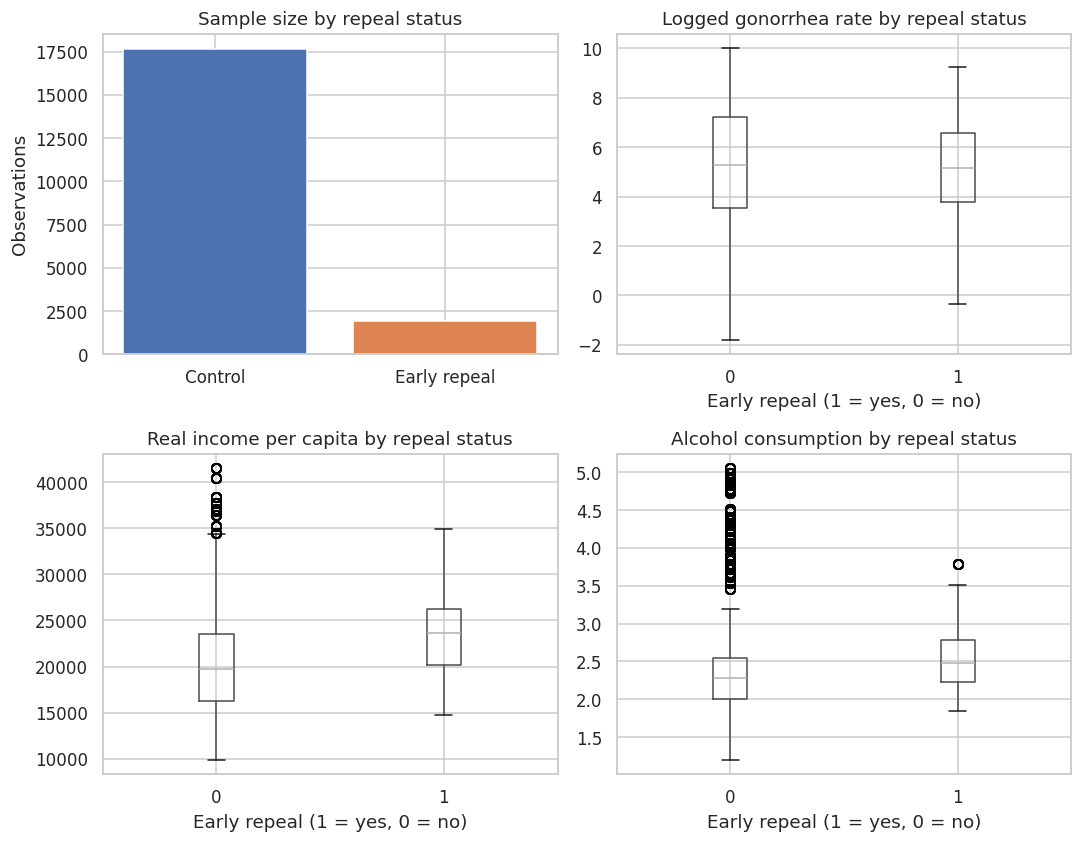

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
counts = abortion_df["repeal"].value_counts().sort_index()
axes[0, 0].bar(["Control", "Early repeal"], [counts.get(0, 0), counts.get(1, 0)], color=["#4C72B0", "#DD8452"])
axes[0, 0].set_title("Sample size by repeal status")
axes[0, 0].set_ylabel("Observations")

abortion_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal status")
axes[0, 1].set_xlabel("Early repeal (1 = yes, 0 = no)")

abortion_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal status")
axes[1, 0].set_xlabel("Early repeal (1 = yes, 0 = no)")

abortion_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal status")
axes[1, 1].set_xlabel("Early repeal (1 = yes, 0 = no)")

fig.suptitle("")
fig.tight_layout()
plt.show()


### Prepare covariates and split

The outcome is `lnr`. The treatment is `repeal`. Rows with a missing outcome are dropped. `fa` is missing outside the younger age group, so that column is dropped instead of deleting those rows. Remaining covariates are standardized so the logistic propensity model is on a comparable scale. The split is 80% training and 20% test.

In [10]:
from sklearn.preprocessing import StandardScaler

feature_names = [col for col in abortion_df.columns if col not in ("lnr", "repeal")]
work = abortion_df.copy()
missing_cols = [col for col in feature_names if work[col].isna().any()]
feature_names = [col for col in feature_names if col not in missing_cols]
work = work.dropna(subset=["lnr", "repeal", *feature_names])
X_raw = work[feature_names].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
keep = X_raw.var(axis=0) > 1e-10
X_raw = X_raw[:, keep]
feature_names = [name for name, flag in zip(feature_names, keep) if flag]
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
Y = work["lnr"].to_numpy(dtype=float)
W = work["repeal"].to_numpy(dtype=int)
print("Dropped columns with missing values:", missing_cols)
print("Covariates used:", feature_names)
print("N =", len(Y), " treated =", int(W.sum()), " control =", int((W == 0).sum()))

rng = np.random.default_rng(42)
n = len(Y)
train_idx = rng.choice(n, size=round(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
print("Training set size:", len(Y_train))
print("Test set size:", len(Y_test))
print("Training treated share:", round(float(W_train.mean()), 3))
print("Test treated share:", round(float(W_test.mean()), 3))


Dropped columns with missing values: ['fa']
Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
N = 17921  treated = 1854  control = 16067
Training set size: 14337
Test set size: 3584
Training treated share: 0.103
Test treated share: 0.104


### Train Causal XGBoost on Training Data

`CXGBoost` fits boosted outcome models for each treatment arm and a logistic propensity model.

- `n_estimators` and `max_depth` control the boosters.
- `learner="xgb"` selects XGBoost.
- `fit(X, treatment, y, feature_names=None)` trains on the covariate matrix, binary treatment, and observed outcome.
- `predict(X)` returns the CATE.
- `feature_importance()` ranks covariates for the treatment-effect models.
- Propensity scores are `propensity_.predict_proba(X)[:, 1]`.


In [11]:
cx_model = CXGBoost(n_estimators=80, max_depth=4, learner="xgb", random_state=0)
cx_model.fit(X_train, W_train, Y_train, feature_names=feature_names)
print("mean training CATE:", round(float(cx_model.predict(X_train).mean()), 4))


mean training CATE: -0.1655


The sample **ATE** on the training set is the mean of the predicted conditional effects. `predict()` returns one CATE per row.

In [12]:
cate_train = cx_model.predict(X_train)
print("Training sample ATE (mean CATE):", round(float(cate_train.mean()), 4))


Training sample ATE (mean CATE): -0.1655


The **ATE** is the average of the predicted conditional effects. Here that average is the estimated effect of early repeal on the log gonorrhea rate among 15–19 year olds.

### Prediction

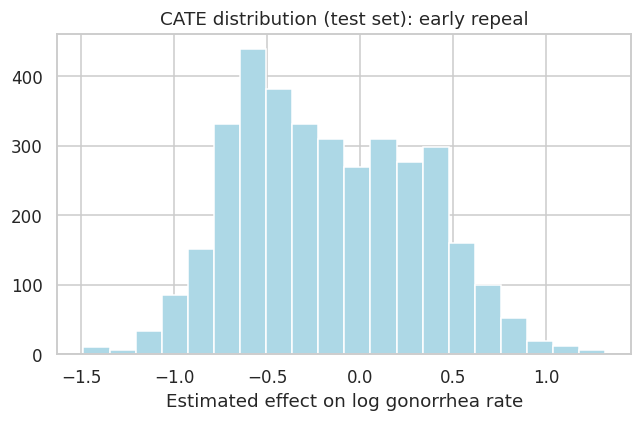

In [13]:
cate_test_pred = cx_model.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(cate_test_pred, bins=20, color="lightblue", edgecolor="white")
ax.set_title("CATE distribution (test set): early repeal")
ax.set_xlabel("Estimated effect on log gonorrhea rate")
fig.tight_layout()
plt.show()


### CATE summary and sample ATE

C-XGBoost does not implement RATE/AUTOC; the causal-forest notebook shows that ranking metric. Below we summarize CATE heterogeneity on the test set and the sample ATE.

In [14]:
print(f"CATE on test set: mean = {cate_test_pred.mean():.3f}, sd = {cate_test_pred.std():.3f}")
print("Sample ATE (test):", round(float(cate_test_pred.mean()), 4))
print("Range:", round(float(cate_test_pred.min()), 3), "to", round(float(cate_test_pred.max()), 3))

test_raw = pd.DataFrame(X_raw[test_idx], columns=feature_names)
test_raw["cate"] = cate_test_pred
for col in ("sex", "bf15"):
    if col in test_raw.columns:
        print(f"\nMean CATE by {col}:")
        print(test_raw.groupby(col)["cate"].agg(["mean", "std", "count"]).round(3))


CATE on test set: mean = -0.169, sd = 0.482
Sample ATE (test): -0.1687
Range: -1.488 to 1.319

Mean CATE by sex:
      mean    std  count
sex                     
1.0 -0.140  0.484   1832
2.0 -0.199  0.477   1752

Mean CATE by bf15:
       mean    std  count
bf15                     
0.0  -0.155  0.483   3457
1.0  -0.533  0.225    127


### Evaluation

Both potential outcomes are not observed here, so PEHE is not identified. What can be checked is how well the arm-specific outcome models predict the factual outcome, and how wide the estimated effects are. The synthetic example above is where PEHE and ATE error are reported, because both potential outcomes were generated.


In [15]:
y0_hat = cx_model.mu0_.predict(X_test)
y1_hat = cx_model.mu1_.predict(X_test)
factual_hat = np.where(W_test == 1, y1_hat, y0_hat)
factual_rmse = float(np.sqrt(np.mean((factual_hat - Y_test) ** 2)))
print({
    "factual_RMSE": round(factual_rmse, 3),
    "ATE_hat": round(float(cate_test_pred.mean()), 3),
    "CATE_sd": round(float(cate_test_pred.std()), 3),
})


{'factual_RMSE': 0.625, 'ATE_hat': -0.169, 'CATE_sd': 0.482}


### Variable importance (XGBoost)

`feature_importance()` returns the mean importance of the treatment-effect models (`tau0_` and `tau1_`). The plot ranks covariates by that score.


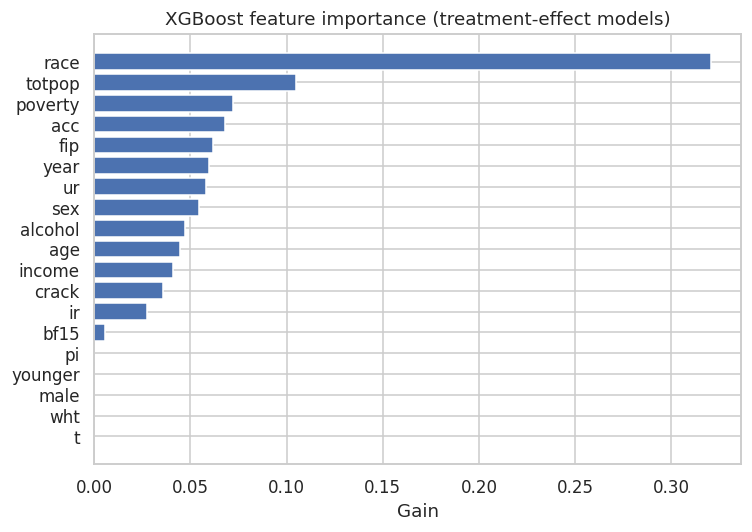

In [16]:
imp = cx_model.feature_importance()
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(np.array(feature_names)[order], imp[order], color="#4C72B0")
ax.set_xlabel("Gain")
ax.set_title("XGBoost feature importance (treatment-effect models)")
fig.tight_layout()
plt.show()


### SHAP analysis

SHAP values for the CATE predictions come from `explain()`. A subsample of the training data is used so the permutation explainer stays small.


In [17]:
sv = cx_model.explain(X_train, max_samples=40, random_state=42)
print("SHAP array shape:", sv.values.shape)
print("Top features by mean |SHAP|:")
order = np.argsort(sv.importance())[::-1]
for name, score in zip(np.array(sv.feature_names)[order][:8], sv.importance()[order][:8]):
    print(f"  {name}: {score:.4f}")


SHAP array shape: (40, 19)
Top features by mean |SHAP|:
  race: 0.3035
  poverty: 0.1955
  acc: 0.1212
  totpop: 0.0988
  ur: 0.0879
  year: 0.0655
  alcohol: 0.0505
  ir: 0.0399


In [18]:
print("Explained rows:", len(sv.predictions))
print("Mean explained CATE:", round(float(sv.predictions.mean()), 4))


Explained rows: 40
Mean explained CATE: -0.1128


#### Importance plot (bar / beeswarm)

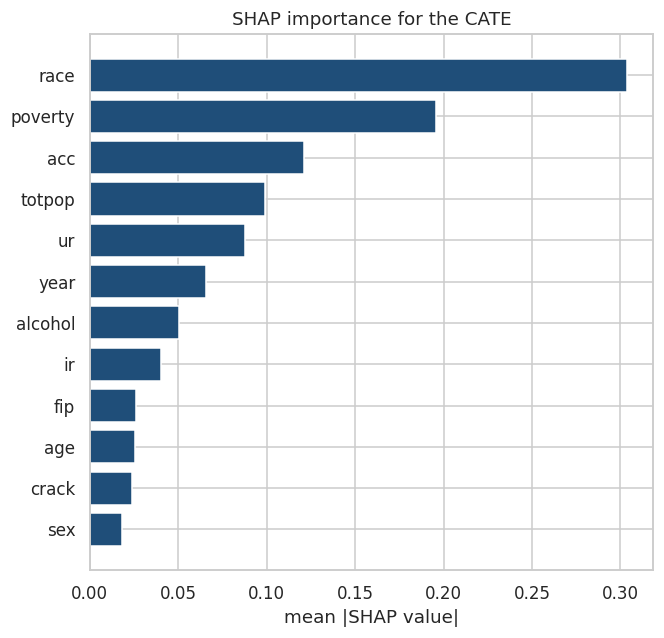

In [19]:
sv.plot_importance(max_display=12)
plt.show()


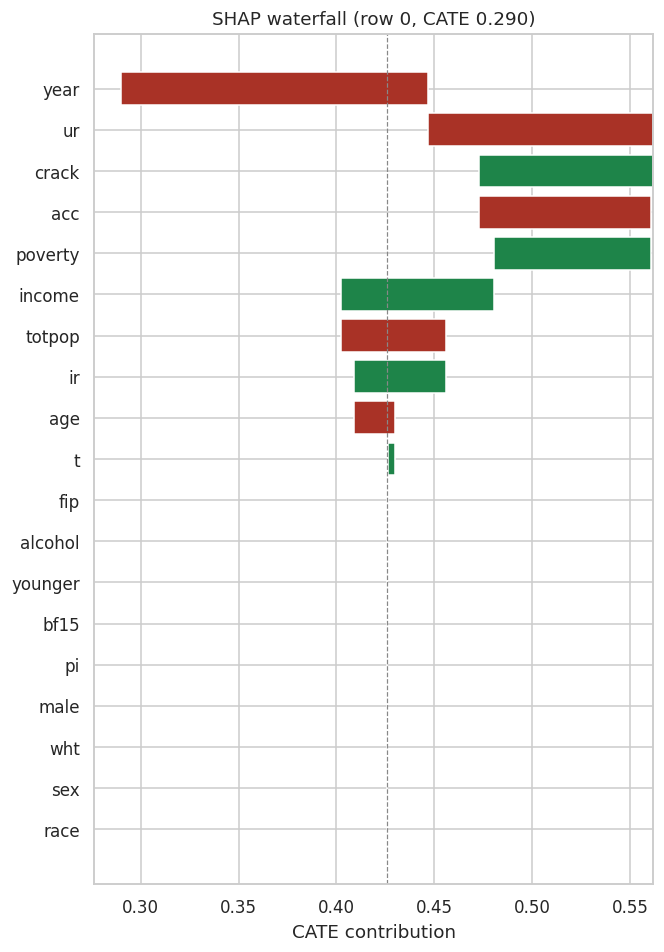

In [20]:
sv.plot_waterfall(row=0)
plt.show()


#### SHAP dependence

Each panel shows how the SHAP value for the conditional effect changes with one covariate.

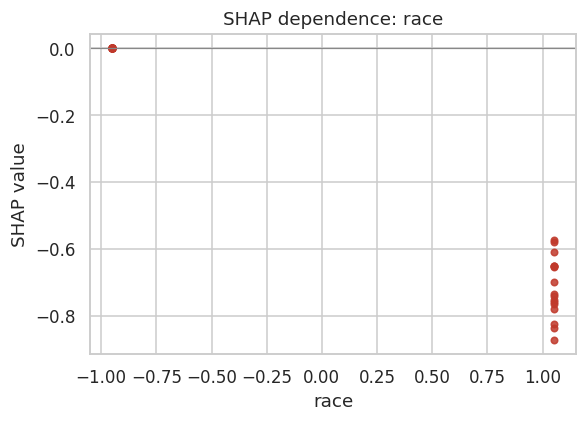

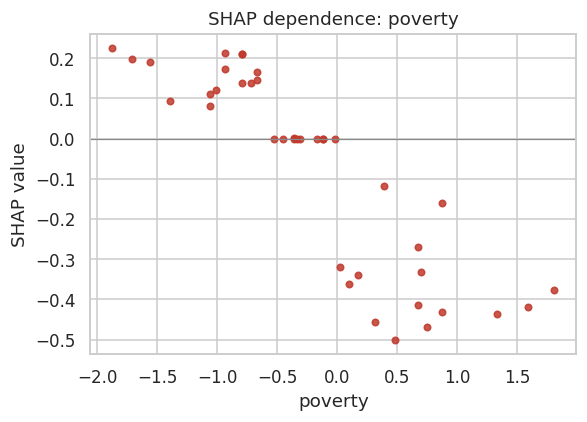

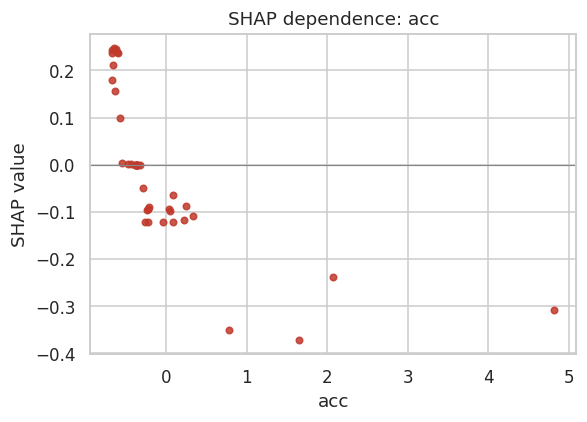

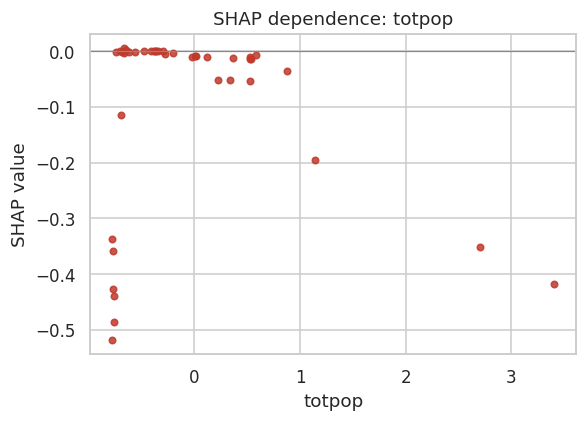

In [21]:
top_features = list(np.array(sv.feature_names)[np.argsort(sv.importance())[::-1][:4]])
for name in top_features:
    sv.plot_dependence(name)
    plt.show()


#### Decompose single predictions

The waterfall plot shows how each feature moves the predicted conditional effect for one observation away from the baseline.

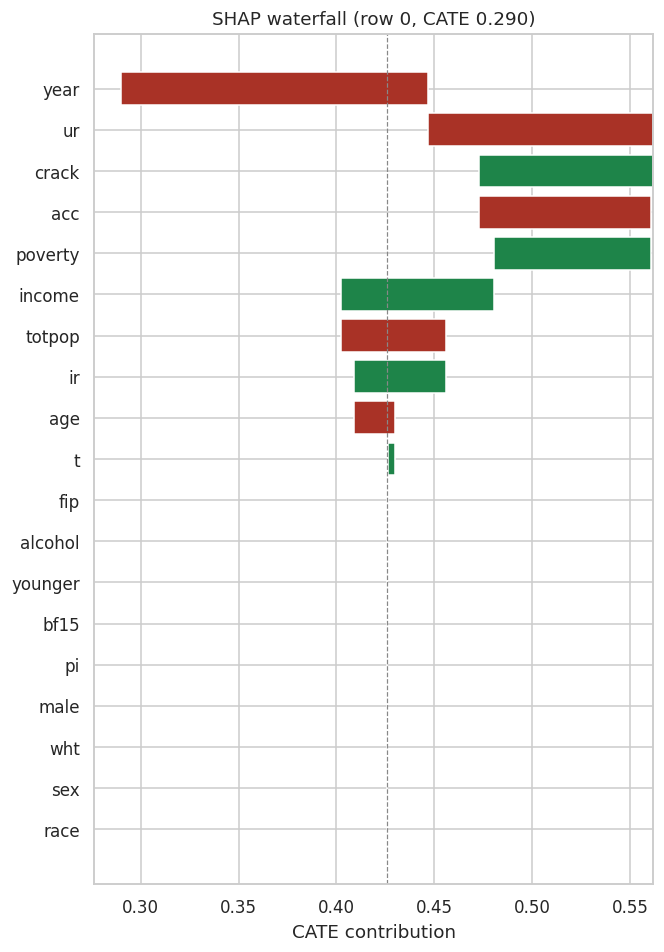

In [22]:
sv.plot_waterfall(row=0)
plt.show()


#### Averaged SHAP values (importance by subgroup)

The bar chart above averages absolute SHAP values over the explained rows. The waterfall below is one explained row with `sex == 2` (female), when that row is in the explained sample.

Waterfall for a training row with sex = 2.0


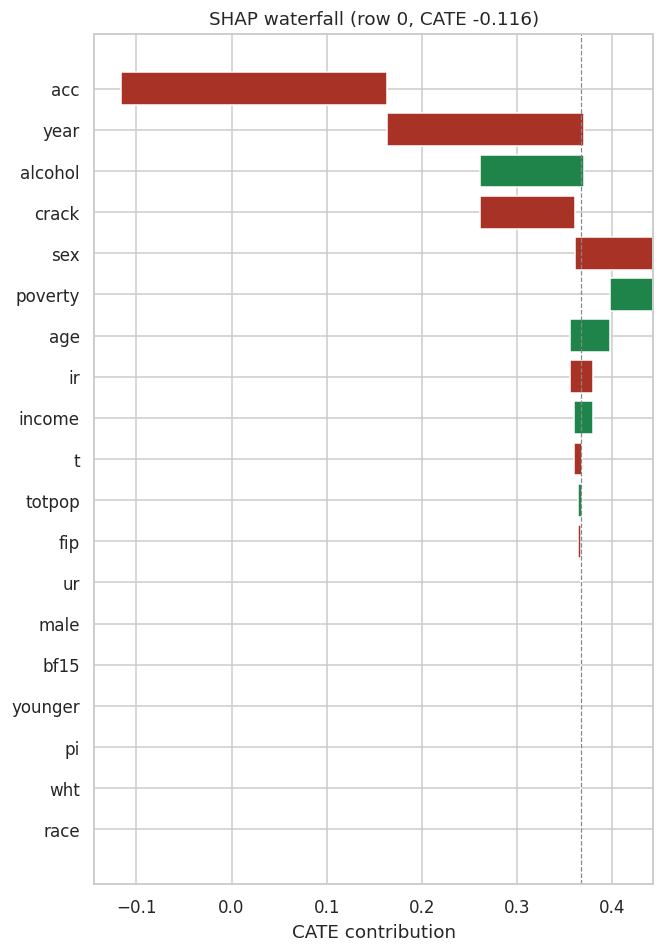

In [23]:
sex_col = feature_names.index("sex")
female_idx = np.flatnonzero(np.isclose(X_raw[train_idx, sex_col], 2))
sv_female = cx_model.explain(
    X_train[female_idx[:30]],
    background=X_train,
    max_samples=30,
    random_state=42,
)
print("Waterfall for a training row with sex =", X_raw[train_idx[female_idx[0]], sex_col])
sv_female.plot_waterfall(row=0)
plt.show()


### Propensity scores

C-XGBoost fits a separate logistic propensity model and stores it on `propensity_`. These scores are not used in the outcome loss. They are useful for overlap diagnostics or weighting.


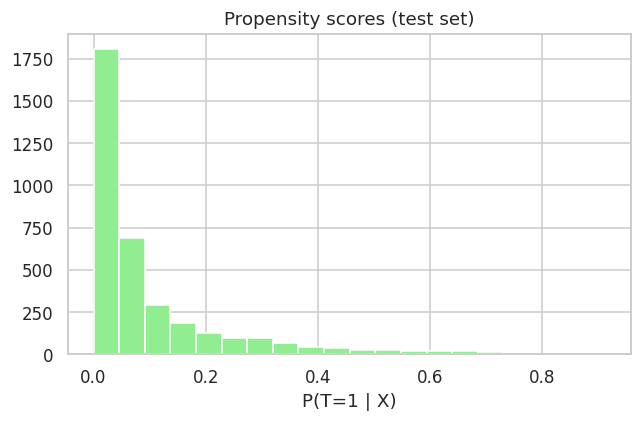

In [24]:
ps_test = cx_model.propensity_.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(ps_test, bins=20, color="lightgreen", edgecolor="white")
ax.set_title("Propensity scores (test set)")
ax.set_xlabel("P(T=1 | X)")
fig.tight_layout()
plt.show()


## Summary and Conclusion

C-XGBoost estimates heterogeneous treatment effects with a boosted X-learner. Separate outcome models predict the potential outcomes under control and treatment, a second pair of boosters fits the imputed treatment effects, and a logistic propensity model combines the two effect surfaces. `predict()` returns the conditional average treatment effect. `feature_importance()` ranks covariates in the effect models, and `propensity_` supplies overlap diagnostics.

This tutorial fit `CXGBoost` on a simulation, where both potential outcomes are known, and on the **abortion** dataset from `causaldata`. On that study the outcome is the logged gonorrhea rate (`lnr`) and the treatment is early repeal (`repeal`). The observational example reports the sample average treatment effect, factual outcome fit, covariate importance, SHAP attributions, and propensity scores.

Further reading below covers the related literature.

## Resources

1.  C-XGBoost: two-head XGBoost with treatment masking for causal inference. The Python class is `CXGBoost` in PyCausalML.

2.  DragonNet-style outcome regression: Shi et al., "Adapting Neural Networks for the Estimation of Treatment Effects" (2019).

3.  Athey, Tibshirani, and Wager. "Generalized Random Forests." Annals of Statistics, 47(2), 2019.
